# Song identification from hummed and whistled raw audio interpretations

# 1 Author

**Alexa García Nuñez**


# 2 Problem formulation


The task is to build a multi-class audio classification system that identifies which of 8 songs is being hummed or whistled from a 10 second recording. The input to the system is a raw audio file and the output is one of 8 possible discrete song labels. Our data consists of 800 audio clips across 8 classes, giving approximately 100 examples per class. This makes it a supervised learning problem. A random classifier would achieve 12.5% accuracy by chance, so this serves as our baseline. This means that any meaningful model should beat it.

What makes this problem difficult is that the same song sounds very different depending on the speaker, their vocal range, and whether they are humming or whistling. There are no consistent instruments or lyrics to rely on. The model must learn  deeper structural patterns through feature extraction that generalise across these sources of variation, using only the audio signal as input. A further challenge is the limited dataset size. With only 800 samples the model has relatively little data to learn from, which increases the risk of overfitting. 

The problem is interesting because from an ML perspective, it is a good example of a problem where raw input data is not directly usable and must first be transformed into a meaningful feature representation before any classifier can be applied. 



# 3 Methodology

For the training task, I give the model labelled audio clips so it can learn the relationship between extracted features and song labels. For the data split, 80% of speakers are assigned to training, 10% to validation, and 10% to testing. It is important to note that I split speakers, not clips. This is done to prevent speaker leakage, which occurs when the same voice appears in both training and a val or test set. 

For each classifier I will adjust its internal parameters to minimise classification error on training data (weights for logistic regression, boundary for SVM, K for KNN). Training accuracy will be observed but not used for model selection it is only compared against validation accuracy to assess overfitting. A large gap between the two suggests the model has memorised training data rather than learned generalisable patterns.

Validation performance is judged by both accuracy and a confusion matrix. The confusion matrix reveals patterns in errors, e.g  whether the same two songs are consistently confused, which would suggest their features are not distinguishing enough. These metrics are used to compare all pipelines. Once the best pipeline is identified, the test set is used exactly once to produce a final honest performance estimate. No further tuning is done after this point.

Beyond speaker leakage, a secondary concern in classification tasks distribution mismatch (Masiha et al., 2022, p. 1.). Since many speakers recorded only hums or only whistles, a standard speaker split would produce partitions with unequal hum/whistle ratios. A stratified group split was implemented to address this, as described in Section 5.




# 4 Implemented ML prediction pipelines

The pipelines I am implementing can be split into two families: one using audio feature extraction and the other using image features from mel spectrograms. Each pipeline consists of four stages: data loading, feature extraction, normalisation, and classification, as shown in the diagram below.

Three audio feature sets are explored: MFCCs only (A1), MFCCs with delta and delta-delta coefficients (A2), and a fully extended set adding chroma, spectral centroid, rolloff, bandwidth, zero crossing rate and tempo (A3). 

Three image feature sets are explored: LBP texture features alone (B1), LBP with mel band statistics (B2), and LBP combined with HOG and mel band statistics (B3).

A final combined pipeline (C) concatenates the best audio features (A3) with B2 (LBP + mel band statistics). This combination was decided mid experiment after observing that A3+B3 would produce far too many features relative to the number of training sample.  

The feature extraction stage is explored across these seven approaches. The classification stage will explore five different models which creates five new pipeline  variants. The models are logistic regression, KNN, SVM with RBF kernel, Naive Bayes, and a soft voting ensemble of logistic regression, KNN and SVM.

The splitting and normalisation stages remain identical across all pipelines to ensure differences in validation accuracy are attributable to feature and model choices, not data preparation.Within each pipeline, all transformation parameters including feature extraction, scaler statistics, and model weights are fixed at training time and remain unchanged through validation and testing. My comparisons are made across pipelines, not within them.


Note: the diagram below illustrates the overall pipeline structure.The input is the 10 second long raw .wav audio file and the output is one of the 8 predicted song labels. Each combination of feature extraction approach and classifier I explored constitutes a distinct pipeline. The bullets within each stage represent the options I explored, not simultaneous operations.


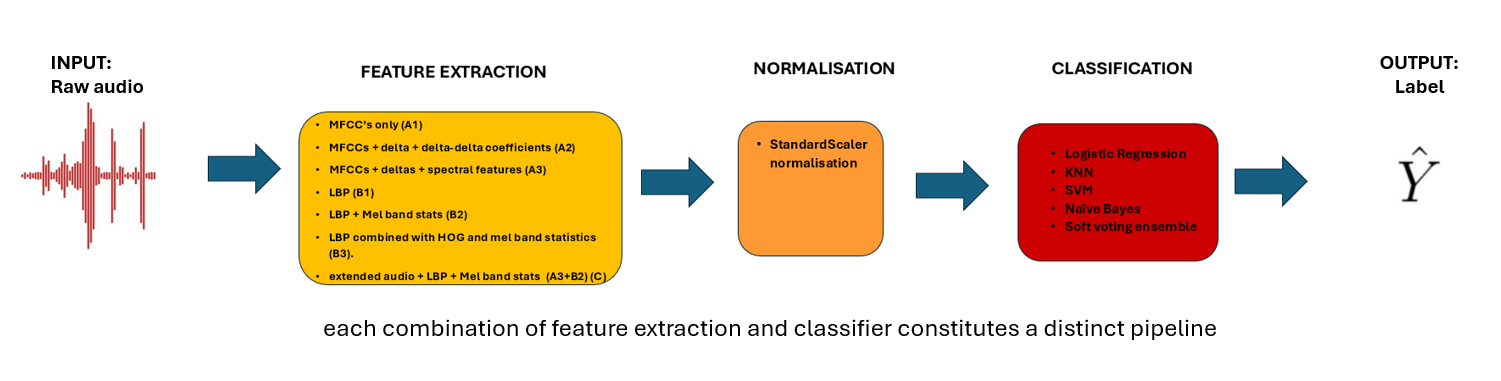


## 4.1 Transformation stage

For the feature extraction stage, for the sake of standardisation , all clips will be resampled to 16kHz on loading using librosa's built- n resampling, giving 160,000 samples per 10-second clip. I will explore two families of features. For audio-based features I will use librosa to extract perceptual features, including Mel Frequency Cepstral Coefficients (MFCCs) and their delta derivatives because they emulate the human auditory system to capture timbre and temporal dynamics (Rezaul et al., 2024). Spectral features such as centroid, rolloff and bandwidth will provide mathematical descriptions of a sound's brightness and tonal characteristics, while chroma features will map spectral energy into twelve semitones to capture pitch relationships, making them particularly suited to music classification (Lhoest et al., 2021). The three audio pipelines will produce feature vectors of 26 (A1), 78 (A2) and 99 (A3) dimensions respectively.
 
For the image-based pipelines, all image features will be derived from the mel spectrogram which is a 2D representation of how energy is distributed across mel frequency bands over time. I will choose LBP and HOG features as they capture local texture and edge orientations within spectrograms, offering robustness to background noise by identifying patterns that remain stable despite interference (Lim et al., 2015; Pathan et al., 2025). Meanwhile, Mel band statistics will be a form of dimensionality reduction through statistical summarisation (Lhoest et al., 2021). B1 will produce 59 features, B2 (LBP + mel band statistics) will produce 187 features, and B3 (LBP + HOG + mel band statistics) will produce 8699 features. The combined pipeline C (A3 + B2) will produce 286 features

Before extracting LBP and HOG features, the mel spectrogram is min-max normalised to the 0–255 range. This is necessary because LBP and HOG are designed for  greyscale images and expect pixel intensities in this range. This per clip normalisation does not cause leakage as it uses only the individual clip's own minimum and maximum values, not statistics from other clips. 

The output of each feature extraction stage will be a 1D numpy array of fixed length, one row per clip, which will then be passed through StandardScaler to be normalised before classification.


## 4.2 Model stage


I will explore five classifiers across all feature sets. Logistic regression learns a linear decision boundary and is fast and interpretable, with regularisation strength controlled by parameter C. KNN classifies by majority vote among the k nearest neighbours, making no distributional assumptions but requiring normalisation due to its distance-based nature. SVM with an RBF kernel finds the maximum-margin boundary in a transformed feature space and is well suited to high-dimensional data. Naive Bayes assumes conditional feature independence and serves as a useful baseline. Finally a soft voting ensemble combines logistic regression, KNN and SVM by averaging their predicted class probabilities, exploiting the diversity between models that make fundamentally different assumptions about the decision boundary. All hyperparameters will be tuned using GridSearchCV with 5-fold stratified cross validation on training data only.


## 4.3 Ensemble stage



A soft voting ensemble combining logistic regression, KNN and SVM will be included as a fifth classifier option for each feature set. Each base model outputs a probability distribution over the 8 song classes, and the ensemble averages these probabilities and predicts the class with the highest average. The three base models will be chosen because they make different assumptions about the decision boundary. Logistic regression will assume a linear relationship, KNN will rely on local similarity between samples, and SVM will find a maximum-margin boundary in a transformed feature space. Having diverse models is important for ensemble performance, as combining models prevents the ensemble from being limited by the specific weaknesses of any single algorithm(Lhoest et al., 2021). 
Each base model in the ensemble will use the same tuned hyperparameters identified during the individual grid search.



# 5 Dataset



Loaded 800 clips | 187 unique speakers
Train: 640 | Val: 80 | Test: 80
No speaker overlap confirmed


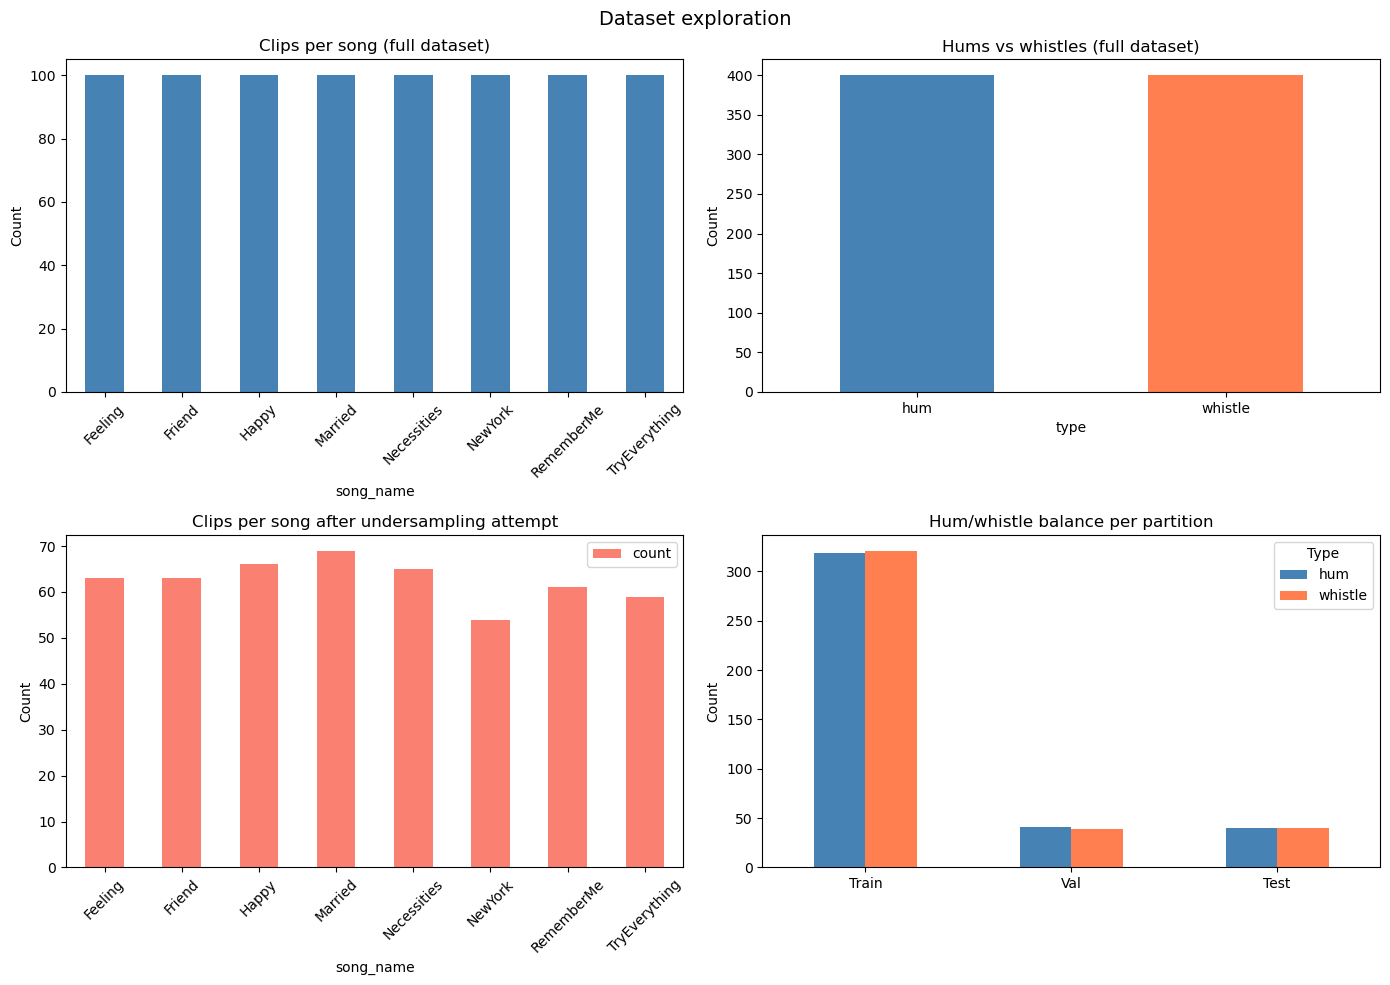

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import urllib.request
import zipfile
import math
from tqdm import tqdm
import librosa
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

#break down file paths 
file_paths = glob.glob('files pml/*.wav')

table = []
for file_path in file_paths:
    parts     = file_path.split('/')[-1].split('_')
    speaker   = parts[0]
    type_     = parts[1]
    number    = parts[2]
    song_name = parts[3].split('.')[0]
    table.append([file_path, song_name, speaker, type_, number])

df = pd.DataFrame(table, columns=['file_path', 'song_name', 'speaker', 'type', 'number'])
print(f'Loaded {len(df)} clips | {df["speaker"].nunique()} unique speakers')
le = LabelEncoder()
df['label'] = le.fit_transform(df['song_name'])

# undersampling attempt
def undersample(df, max_per_type=2):
    balanced = []
    for _, group in df.groupby('speaker'):
        balanced.append(pd.concat([
            group[group['type'] == 'hum'].head(max_per_type),
            group[group['type'] == 'whistle'].head(max_per_type)
        ]))
    return pd.concat(balanced).reset_index(drop=True)

df_balanced = undersample(df, max_per_type=2)

#full data visulisation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df['song_name'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Clips per song (full dataset)')
axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=45)

df['type'].value_counts().plot(
    kind='bar', ax=axes[0,1], color=['steelblue', 'coral'])
axes[0,1].set_title('Hums vs whistles (full dataset)')
axes[0,1].set_ylabel('Count')
axes[0,1].tick_params(axis='x', rotation=0)

#undersampling attempt result graph
df_balanced['song_name'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,0], color='salmon')
axes[1,0].set_title('Clips per song after undersampling attempt')
axes[1,0].set_ylabel('Count')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend()

#stratified data split into train, val and testing
speaker_recording_type  = df.groupby('speaker')['type'].apply(
    lambda x: 'hum_only' if set(x) == {'hum'}
              else 'whistle_only' if set(x) == {'whistle'}
              else 'mixed'
).reset_index()
speaker_recording_type.columns = ['speaker', 'recording_type']


# split speakers by hum/whistle
train_spk, rest_data = train_test_split(
    speaker_recording_type, test_size=0.2, random_state=42,
    stratify=speaker_recording_type['recording_type'])
val_spk, test_spk = train_test_split(
    rest_data, test_size=0.5, random_state=42,
    stratify=rest_data['recording_type'])


#extracting the actual audio files for each speaker allocated to train,val and test
train_speaker_list = train_spk['speaker'].tolist()
val_speaker_list   = val_spk['speaker'].tolist()
test_speaker_list  = test_spk['speaker'].tolist()

train_df = df.query('speaker in @train_speaker_list')
val_df   = df.query('speaker in @val_speaker_list')
test_df  = df.query('speaker in @test_speaker_list')

file_paths_train = train_df['file_path'].values
labels_train     = train_df['label'].values
file_paths_val   = val_df['file_path'].values
labels_val       = val_df['label'].values
file_paths_test  = test_df['file_path'].values
labels_test      = test_df['label'].values

print(f'Train: {len(file_paths_train)} | Val: {len(file_paths_val)} | Test: {len(file_paths_test)}')

# verify no speaker overlap
assert len(set(train_speaker_list) & set(val_speaker_list))  == 0
assert len(set(train_speaker_list) & set(test_speaker_list)) == 0
assert len(set(val_speaker_list)   & set(test_speaker_list)) == 0
print('No speaker overlap confirmed')


#  plot data split hum/whistle proportions
group_proportions = pd.DataFrame({
    'Train': train_df['type'].value_counts(),
    'Val':   val_df['type'].value_counts(),
    'Test':  test_df['type'].value_counts()
})
group_proportions.T.plot(kind='bar', ax=axes[1,1], color=['steelblue', 'coral'])
axes[1,1].set_title('Hum/whistle balance per partition')
axes[1,1].set_ylabel('Count')
axes[1,1].tick_params(axis='x', rotation=0)
axes[1,1].legend(title='Type')
plt.suptitle('Dataset exploration', fontsize=14)
plt.tight_layout()
plt.show()


As seen in the graphs above, the full dataset is perfectly balanced by design with 100 clips per song and an equal split of hums and whistles, though speakers contributed unequally, ranging from 2 to 5 clips each. There is speaker ID is absent from the dataset, speakers run from S1 to S188 but only 187 unique speakers are present.

Because splitting must be done at the speaker level to prevent leakage, I examined the per speaker breakdown and found that 62 speakers recorded only hums and 37 recorded only whistles, meaning a standard speaker split would likely produce partitions with unequal hum/whistle ratios. To address this I first attempted undersampling, capping each speaker at 2 hums and 2 whistles. However since no speaker recorded all 8 songs and several hum-only speakers were the primary contributors to certain songs, this introduced song class imbalance, with counts ranging from 54 to 69 clips per song compared to the original 100, and the overall dataset reducing from 800 to approximately 500 clips.

Since this approach meant losing 300 clips and causing data imbalance I decided to implement a stratified group split, categorising each speaker as hum-only, whistle-only or mixed, then splitting speakers within each category so each partition received a proportional share of all three types. It is worth noting that stratified splitting does not guarantee perfect balance,  it simply preserves whatever proportions exist in the full dataset across each partition. The mixed category introduces some uncertainty since speakers within it vary in their hum/whistle ratio and the stratification does not  account for this. In practice though, as the final graph shows, all three partitions ended up with a near-equal hum/whistle split. This worked out well but is partly due to the way  the mixed speakers were allocated, rather than the stratification alone, and is acknowledged as such.



In [62]:

del file_paths_test, labels_test
print('Test set locked away.')

Test set locked away.


The test set variables are deleted here and will only be recreated in the final evaluation cell. This prevents any accidental use of test data during experimentation. The test speaker list remains in memory because it contains only speaker IDs, not audio content or labels.

# 6 Experiments and results


### check spectogram images

Before starting any experiments I wanted to have a look at the spectrograms. The task requires an input of 10 seconds however there is no specification of where in the clip that 10 seconds needs to start. I initially attempted to offset the loading point to skip the opening seconds as some clips contain noise from speakers preparing to hum or whistle. However, some clips were too short to load a full 10 seconds from a later offset, producing inconsistent feature vector lengths. I therefore load all clips from second 0. Below are spectrograms for two songs to illustrate the variation between hums and whistles.

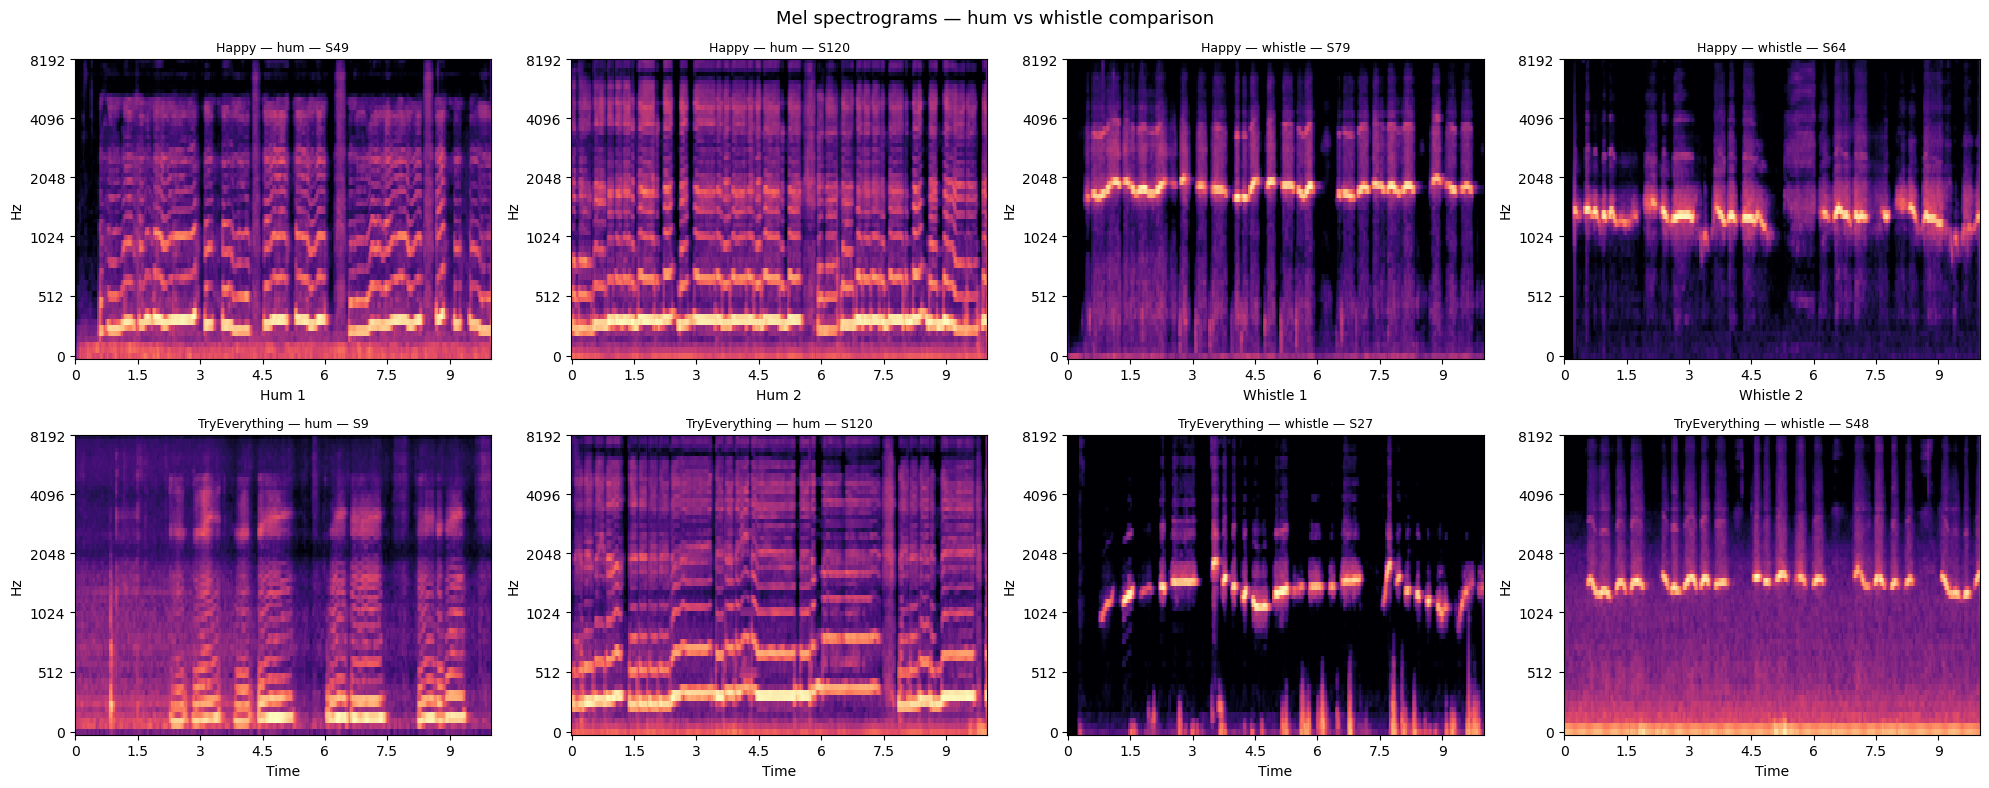

In [63]:
songs_to_plot = ['Happy', 'TryEverything']
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for row_idx, song in enumerate(songs_to_plot):
    song_df  = df[df['song_name'] == song]
    clips    = pd.concat([
        song_df[song_df['type'] == 'hum'].head(2),
        song_df[song_df['type'] == 'whistle'].head(2)
    ])
    for col_idx, (_, clip) in enumerate(clips.iterrows()):
        x, sr = librosa.load(clip['file_path'], sr=16000, offset=0, duration=10.0)
        S_db  = librosa.power_to_db(librosa.feature.melspectrogram(y=x, sr=sr, n_mels=64), ref=np.max)
        librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[row_idx, col_idx])
        axes[row_idx, col_idx].set_title(f"{song} — {clip['type']} — {clip['speaker']}", fontsize=9)

for col_idx, label in enumerate(['Hum 1', 'Hum 2', 'Whistle 1', 'Whistle 2']):
    axes[0, col_idx].set_xlabel(label, fontsize=10)

plt.suptitle('Mel spectrograms — hum vs whistle comparison', fontsize=13)
plt.tight_layout()
plt.show()


The spectrograms reveal clear differences between hums and whistles. It seems that hums concentrate energy in the lower frequency bands while whistles produce higher, narrower frequency bands. However, there is  noticeable variation even within the same type and song (e.g bottom left two spectrograms). These observations suggest image features alone may struggle to distinguish songs reliably across different speakers, but may add complementary information alongside audio features. This motivated the decision to explore both feature families and combine the best of each  in feature combination (C) as per my pipeline diagram in the methodology section.


### extract features

In [65]:
from skimage.feature import hog, local_binary_pattern
from tqdm import tqdm

#extract audio features

def get_mfcc(file_path, n_mfcc=13, sr=16000):
    x, sr = librosa.load(file_path, sr=sr, offset=0, duration=10.0)
    mfcc  = librosa.feature.mfcc(y=x, sr=sr, n_mfcc=n_mfcc)
    return np.concatenate([np.mean(mfcc, axis=1), np.std(mfcc, axis=1)])

def get_mfcc_DD(file_path, n_mfcc=13, sr=16000):
    x, sr     = librosa.load(file_path, sr=sr, offset=0, duration=10.0)
    mfcc      = librosa.feature.mfcc(y=x, sr=sr, n_mfcc=n_mfcc)
    delta     = librosa.feature.delta(mfcc)
    delta2    = librosa.feature.delta(mfcc, order=2)
    return np.concatenate([
        np.mean(mfcc,   axis=1), np.std(mfcc,   axis=1),  
        np.mean(delta,  axis=1), np.std(delta,  axis=1),  
        np.mean(delta2, axis=1), np.std(delta2, axis=1)])

    

def get_extended(file_path, n_mfcc=13, sr=16000):
    x, sr     = librosa.load(file_path, sr=sr,offset=0, duration=10.0)
    mfcc      = librosa.feature.mfcc(y=x, sr=sr, n_mfcc=n_mfcc)
    delta     = librosa.feature.delta(mfcc)
    delta2    = librosa.feature.delta(mfcc, order=2)
    chroma    = librosa.feature.chroma_stft(y=x, sr=sr)
    centroid  = librosa.feature.spectral_centroid(y=x, sr=sr)
    rolloff   = librosa.feature.spectral_rolloff(y=x, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(y=x, sr=sr)
    zcr       = librosa.feature.zero_crossing_rate(y=x)
    tempo, _  = librosa.beat.beat_track(y=x, sr=sr)
    return np.concatenate([
        np.mean(mfcc,   axis=1), np.std(mfcc,   axis=1),  
        np.mean(delta,  axis=1), np.std(delta,  axis=1),  
        np.mean(delta2, axis=1), np.std(delta2, axis=1),  
        np.mean(chroma, axis=1),                           
        [np.mean(centroid), np.std(centroid)],             
        [np.mean(rolloff),  np.std(rolloff)],              
        [np.mean(bandwidth),np.std(bandwidth)],            
        [np.mean(zcr),      np.std(zcr)],                  
        [float(np.squeeze(tempo))]                         
    ])                                                     

# extract image features 

def get_lbp(file_path, n_mels=64, sr=16000):
    x, sr   = librosa.load(file_path, sr=sr, offset=0, duration=10.0)
    S       = librosa.feature.melspectrogram(y=x, sr=sr, n_mels=n_mels)
    S_db    = librosa.power_to_db(S, ref=np.max)
    S_norm  = ((S_db - S_db.min()) / (S_db.max() - S_db.min()) * 255).astype(np.uint8)
    lbp     = local_binary_pattern(S_norm, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=59, range=(0, 59), density=True)
    return hist
    
def get_lbp_mel(file_path, n_mels=64, sr=16000):
    x, sr   = librosa.load(file_path, sr=sr, offset=0, duration=10.0)
    S       = librosa.feature.melspectrogram(y=x, sr=sr, n_mels=n_mels)
    S_db    = librosa.power_to_db(S, ref=np.max)
    S_norm  = ((S_db - S_db.min()) / (S_db.max() - S_db.min()) * 255).astype(np.uint8)
    lbp     = local_binary_pattern(S_norm, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=59, range=(0, 59), density=True)
    mel_stats = np.concatenate([np.mean(S_db, axis=1), np.std(S_db, axis=1)])
    return np.concatenate([hist, mel_stats])

def get_image_combined(file_path, n_mels=64,sr=16000):
    x, sr   = librosa.load(file_path, sr=sr, offset=0, duration=10.0)
    S       = librosa.feature.melspectrogram(y=x, sr=sr, n_mels=n_mels)
    S_db    = librosa.power_to_db(S, ref=np.max)
    S_norm  = ((S_db - S_db.min()) / (S_db.max() - S_db.min()) * 255).astype(np.uint8)
    lbp     = local_binary_pattern(S_norm, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=59, range=(0, 59), density=True)
    hog_f   = hog(S_norm, orientations=8, pixels_per_cell=(8, 8),
                  cells_per_block=(2, 2), feature_vector=True)
    mel_stats = np.concatenate([np.mean(S_db, axis=1), np.std(S_db, axis=1)])
    return np.concatenate([hist, hog_f, mel_stats])
    

def getXy(file_paths, labels, extractor):
    X, y = [], []
    for file_path, label in tqdm(zip(file_paths, labels), total=len(file_paths)):
        X.append(extractor(file_path))
        y.append(label)
    return np.array(X), np.array(y)

# extract
print('Extracting A1 — MFCCs Only...')
X_train_A1, y_train = getXy(file_paths_train, labels_train, get_mfcc)
X_val_A1,   y_val   = getXy(file_paths_val,   labels_val,   get_mfcc)

print('Extracting A2 — MFCCs + deltas ...')
X_train_A2, _ = getXy(file_paths_train, labels_train, get_mfcc_DD)
X_val_A2,   _ = getXy(file_paths_val,   labels_val,   get_mfcc_DD)

print('Extracting A3 — MFCCs + deltas + spectral + time features...')
X_train_A3, _ = getXy(file_paths_train, labels_train, get_extended)
X_val_A3,   _ = getXy(file_paths_val,   labels_val,   get_extended)

print('Extracting B1 — LBP ...')
X_train_B1, _ = getXy(file_paths_train, labels_train, get_lbp)
X_val_B1,   _ = getXy(file_paths_val,   labels_val,   get_lbp)

print('Extracting B2 — LBP + mel band stats...')
X_train_B2, _ = getXy(file_paths_train, labels_train, get_lbp_mel)
X_val_B2,   _ = getXy(file_paths_val,   labels_val,   get_lbp_mel)

print('Extracting B3 — LBP + HOG + mel band stats...')
X_train_B3, _ = getXy(file_paths_train, labels_train, get_image_combined)
X_val_B3,   _ = getXy(file_paths_val,   labels_val,   get_image_combined)

print('Combining A3 and B2 to create feature set C...')
X_train_C = np.concatenate([X_train_A3, X_train_B2], axis=1)
X_val_C   = np.concatenate([X_val_A3,   X_val_B2],   axis=1)

print(f'\nA1 shape: {X_train_A1.shape}')
print(f'A2 shape: {X_train_A2.shape}')
print(f'A3 shape: {X_train_A3.shape}')
print(f'B1 shape: {X_train_B1.shape}')
print(f'B2 shape: {X_train_B2.shape}')
print(f'B3 shape: {X_train_B3.shape}')
print(f'C  shape: {X_train_C.shape}')


Extracting A1 — MFCCs Only...


100%|██████████| 80/80 [00:01<00:00, 66.98it/s]


Extracting A2 — MFCCs + deltas ...


100%|██████████| 80/80 [00:01<00:00, 62.77it/s]


Extracting A3 — MFCCs + deltas + spectral + time features...


...

Extracting B2 — LBP + mel band stats...


100%|██████████| 80/80 [00:01<00:00, 59.60it/s]


Extracting B3 — LBP + HOG + mel band stats...


100%|██████████| 80/80 [00:01<00:00, 46.71it/s]

Combining A3 and B2 to create feature set C...

A1 shape: (640, 26)
A2 shape: (640, 78)
A3 shape: (640, 99)
B1 shape: (640, 59)
B2 shape: (640, 187)
B3 shape: (640, 8699)
C  shape: (640, 286)


After feature extraction no further feature selection was applied to reduce the feature sets. For feature set B3, the feature vectors contain 8699 features against only 640 training clips, meaning there are far more dimensions than samples. This risks the models perfectly memorising training data, leading to overfitting. Initially I considered combining A3 with B3 for the C pipeline, but seeing the shapes （99 + 8699 = 8798 features） would only worsen the curse of dimensionality further. Instead C combines A3 with B2 (99 + 187 = 286 features), keeping the feature to sample ratio manageable.

####  normalise features

For normalisation, StandardScaler is fitted on training data only within each pipeline loop and evaluation cell. This ensures the scaler has no knowledge of the validation or test data, preventing leakage.

####  tune model hyperparameters 

In [69]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

feature_sets = {
    'A1 MFCCs':           (X_train_A1, X_val_A1),
    'A2 MFCCs + delta':   (X_train_A2, X_val_A2),
    'A3 Extended':        (X_train_A3, X_val_A3),
    'B1 LBP':             (X_train_B1, X_val_B1),
    'B2 LBP + Mel':       (X_train_B2, X_val_B2),
    'B3 Image Combined':  (X_train_B3, X_val_B3),
    'C A3 + B2':          (X_train_C,  X_val_C),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# hyper parameter tuning

param_grids = {
    'Logistic regression': (
        Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000))]),
        {'clf__C':  [0.00005,0.0001, 0.001,0.01, 0.1, 1, 10, 100]}
    ),
    'KNN': (
        Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier())]),
        {'clf__n_neighbors': [15, 21, 31, 41, 51,61,71,81]}
    ),
    'SVM': (
        Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', probability=True))]),
        {'clf__C': [0.1, 1, 10, 100,1000], 'clf__gamma': ['scale', 'auto']}
    ),
    'Naive Bayes': (
        Pipeline([('scaler', StandardScaler()), ('clf', GaussianNB())]),
        {}
    ),
}

best_params = {}
for feat_name, (X_tr, X_v) in feature_sets.items():
    print(f'\nTuning {feat_name}...')
    best_params[feat_name] = {}

    for clf_name, (pipe, grid) in param_grids.items():
        if not grid:
            best_params[feat_name][clf_name] = {}
            continue

        search = GridSearchCV(pipe, grid, cv=cv, scoring='accuracy', n_jobs=-1)
        search.fit(X_tr, y_train)

        best_params[feat_name][clf_name] = search.best_params_
        print(f'  {clf_name:20s} best params: {search.best_params_}')  




Tuning A1 MFCCs...
  Logistic regression  best params: {'clf__C': 0.1}
  KNN                  best params: {'clf__n_neighbors': 41}
  SVM                  best params: {'clf__C': 1, 'clf__gamma': 'scale'}

Tuning A2 MFCCs + delta...
  Logistic regression  best params: {'clf__C': 0.1}
  KNN                  best params: {'clf__n_neighbors': 71}
  SVM                  best params: {'clf__C': 1, 'clf__gamma': 'scale'}

Tuning A3 Extended...
  Logistic regression  best params: {'clf__C': 0.01}
  KNN                  best params: {'clf__n_neighbors': 61}
  SVM                  best params: {'clf__C': 1, 'clf__gamma': 'scale'}

Tuning B1 LBP...
  Logistic regression  best params: {'clf__C': 100}
  KNN                  best params: {'clf__n_neighbors': 61}
  SVM                  best params: {'clf__C': 10, 'clf__gamma': 'auto'}

Tuning B2 LBP + Mel...
  Logistic regression  best params: {'clf__C': 1}
  KNN                  best params: {'clf__n_neighbors': 71}
  SVM                  best par

Hyperparameter tuning was performed using the GridSearchCV function which uses a 5 fold cross validation process on the training data to find the best hyperparameter out of a predefined set. Notably to avoid leakage the raw feature sets were inputed into the function and the StandardScaler was placed inside the Pipeline object to ensure scaling is fitted fresh on each fold.The grid search was run iteratively starting with reasonable default ranges for each model (e.g 0.01 to 100 range for log regression C value) . This meant when the recommended hyperparameter hit the upper or lower boundary of the search range, the range was extended and the search repeated. The final hyperparameters shown above reflect the settled values after this process.






####  run pipelines and visualise results

In [70]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


results = []

for feat_name, (X_tr, X_v) in feature_sets.items():
    params = best_params[feat_name]

    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_v_sc  = scaler.transform(X_v)

    classifiers = {
        'Logistic regression': LogisticRegression(max_iter=1000, **{k.replace('clf__',''):v for k,v in params['Logistic regression'].items()}),
        'KNN':                 KNeighborsClassifier(**{k.replace('clf__',''):v for k,v in params['KNN'].items()}),
        'SVM':                 SVC(kernel='rbf', probability=True, **{k.replace('clf__',''):v for k,v in params['SVM'].items()}),
        'Naive Bayes':         GaussianNB(),
        'Ensemble':            VotingClassifier(estimators=[
                                   ('lr',  LogisticRegression(max_iter=1000, **{k.replace('clf__',''):v for k,v in params['Logistic regression'].items()})),
                                   ('knn', KNeighborsClassifier(**{k.replace('clf__',''):v for k,v in params['KNN'].items()})),
                                   ('svm', SVC(kernel='rbf', probability=True, **{k.replace('clf__',''):v for k,v in params['SVM'].items()}))
                               ], voting='soft')
    }

    for clf_name, clf in classifiers.items():
        clf.fit(X_tr_sc, y_train)
        train_acc = accuracy_score(y_train, clf.predict(X_tr_sc))
        val_acc   = accuracy_score(y_val,   clf.predict(X_v_sc))

        results.append({
            'features':   feat_name,
            'classifier': clf_name,
            'train_acc':  round(train_acc, 3),
            'val_acc':    round(val_acc,   3)
        })
        print(f'{feat_name:20s} | {clf_name:20s} | train: {train_acc:.3f} | val: {val_acc:.3f}')

results_df = pd.DataFrame(results).sort_values('val_acc', ascending=False)
print('\n--- Results table ---')
display(results_df)

A1 MFCCs             | Logistic regression  | train: 0.308 | val: 0.163
A1 MFCCs             | KNN                  | train: 0.239 | val: 0.138
A1 MFCCs             | SVM                  | train: 0.497 | val: 0.200
A1 MFCCs             | Naive Bayes          | train: 0.245 | val: 0.175
A1 MFCCs             | Ensemble             | train: 0.297 | val: 0.100
A2 MFCCs + delta     | Logistic regression  | train: 0.520 | val: 0.225
A2 MFCCs + delta     | KNN                  | train: 0.239 | val: 0.150
A2 MFCCs + delta     | SVM                  | train: 0.714 | val: 0.263
A2 MFCCs + delta     | Naive Bayes          | train: 0.336 | val: 0.163
A2 MFCCs + delta     | Ensemble             | train: 0.537 | val: 0.250
A3 Extended          | Logistic regression  | train: 0.498 | val: 0.300
A3 Extended          | KNN                  | train: 0.287 | val: 0.175
A3 Extended          | SVM                  | train: 0.766 | val: 0.275
A3 Extended          | Naive Bayes          | train: 0.405 | val

,features,classifier,train_acc,val_acc
27,B3 Image Combined,SVM,1.000,0.400
29,B3 Image Combined,Ensemble,1.000,0.350
32,C A3 + B2,SVM,1.000,0.350
34,C A3 + B2,Ensemble,0.808,0.325
30,C A3 + B2,Logistic regression,0.713,0.325
25,B3 Image Combined,Logistic regression,0.773,0.325
14,A3 Extended,Ensemble,0.588,0.312
26,B3 Image Combined,KNN,0.400,0.312
10,A3 Extended,Logistic regression,0.498,0.300
12,A3 Extended,SVM,0.766,0.275


The results show a clear progression across pipeline families. Within the audio family, each feature addition produced genuine improvement. MFCCs alone (A1) achieved a best val accuracy of 0.200, adding delta and delta-delta coefficients (A2) improved this to 0.263, and the full extended feature set (A3) reached 0.312. This confirms that the selected audio features are genuinely useful for song classification and that the additional delta and spectral features add meaningful complexity.

For the image feature sets, LBP alone (B1) achieved only 0.212, adding mel band statistics (B2) improved this to 0.250. Although the improvement is small, it suggests that combining texture features with statistical summaries of mel-band information results in a small but meaningful performance gain.The full image pipeline B3 (LBP + HOG + mel band statistics) achieved the highest validation accuracy of 0.400 with SVM, but with perfect training accuracy of 1.000 which is a clear sign of overfitting given 8699 features against 640 training clips. 

Overall, B3 achieved the highest validation accuracy but its perfect training accuracy and massive feature to sample ratio suggests it will not generalise well to the test set. Overfitting reduction was attempted (see next section). Since these attempts did not improve B3's generalisation, I selected C (A3 + B2) with an ensemble classifier as my final pipeline. C ensemble achieved a validation accuracy of 0.325 with a training accuracy of 0.808, giving a much smaller train/val gap than B3 and shows that the model is getting 20% of training clips wrong and hasn't  entirely memorised the data. Even though C A3 + B2	SVM	has a higher val accuracy than 0.325 it has the same 1.000 training result.The ensemble was also chosen over SVM because its averaged predictions across three diverse classifiers reduce the risk of any single model overfitting. Although C's val accuracy is lower than B3's, the smaller train/val gap suggests it is more likely to generalise to unseen test data and hence produce better accuracy.



Val accuracy: 0.325
Random baseline: 0.125


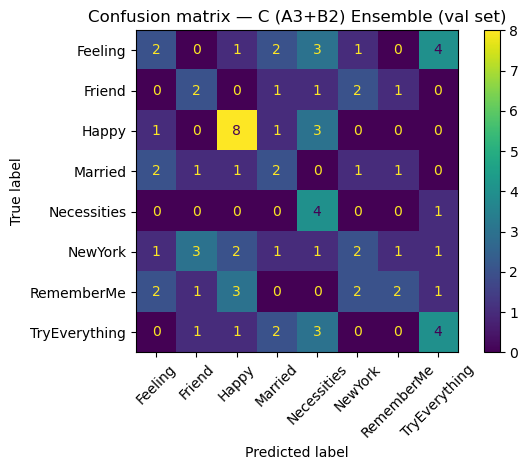

In [68]:
scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train_C)
X_v_sc  = scaler.transform(X_val_C)

params = best_params['C A3 + B2']
clf = VotingClassifier(estimators=[
    ('lr',  LogisticRegression(max_iter=1000, **{k.replace('clf__',''):v for k,v in params['Logistic regression'].items()})),
    ('knn', KNeighborsClassifier(**{k.replace('clf__',''):v for k,v in params['KNN'].items()})),
    ('svm', SVC(kernel='rbf', probability=True, **{k.replace('clf__',''):v for k,v in params['SVM'].items()}))
], voting='soft')

clf.fit(X_tr_sc, y_train)
val_pred = clf.predict(X_v_sc)

print(f'Val accuracy: {accuracy_score(y_val, val_pred):.3f}')
print(f'Random baseline: {1/8:.3f}')

cm   = confusion_matrix(y_val, val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(xticks_rotation=45)
plt.title('Confusion matrix — C (A3+B2) Ensemble (val set)')
plt.tight_layout()
plt.show()

In the confusion matrix we can see Happy is the strongest song with 8 out of 13 correct. Feeling and Married are the weakest, with Feeling's errors spread across multiple classes suggesting its features are not sufficiently distinct. RememberMe is  also frequently misclassified as Happy. Errors are distributed across classes rather than concentrated on one, suggesting that the model is genuinely generalising rather than defaulting to a dominant class.

####  overfitting reduction attempts of B3

Even though B3 achieved the highest validation accuracy, it has 8699 features against only 640 training samples. Hence, in the cell below I will attempt some common ML dimensionality reduction techniques which help prevent overfitting due to redundant or  'noisy' features. I first will try further SVM tuning and regularisation which by reducing the C hyperparameter value ranges in GridSearch, forcing the model to accept more training errors. I then will attempt Principal Component Analysis (PCA) which is a linear projection technique that maps high dimensional data into a lower dimensional space (Abdul Salam et al., 2021). In the literature high correlation filter (HCF) is also mentioned as an effective way to remove redundant features. I think this would be effective on B3 as HOG features in particular are likely to be highly correlated. Removing redundant correlated features could meaningfully reduce the 8699 dimensions. This will also be attempted.


In [45]:

#  increase regularisation by reducing C 
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', probability=True))
])

search = GridSearchCV(pipe_svm,
    {'clf__C': [0.001, 0.01, 0.1, 1], 'clf__gamma': ['scale', 'auto']},
    cv=cv, scoring='accuracy', n_jobs=-1)
search.fit(X_train_B3, y_train)
print(f'Best params: {search.best_params_}')

# evaluate on val set
scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train_B3)
X_v_sc  = scaler.transform(X_val_B3)

clf = SVC(kernel='rbf', probability=True,
          C=search.best_params_['clf__C'],
          gamma=search.best_params_['clf__gamma'])
clf.fit(X_tr_sc, y_train)
print(f'B3 SVM smaller C | train: {accuracy_score(y_train, clf.predict(X_tr_sc)):.3f} | val: {accuracy_score(y_val, clf.predict(X_v_sc)):.3f}')

#  PCA dimensionality reduction before SVM
# reduce 8699 features to 100 principal components before classification

from sklearn.decomposition import PCA

pipe_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=100, random_state=42)),
    ('clf', SVC(kernel='rbf', probability=True))
])

search = GridSearchCV(pipe_pca,
    {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 'auto']},
    cv=cv, scoring='accuracy', n_jobs=-1)
search.fit(X_train_B3, y_train)

print(f'Best params: {search.best_params_}')
print(f'B3 SVM + PCA(100) | train: {accuracy_score(y_train, search.predict(X_train_B3)):.3f} | val: {accuracy_score(y_val, search.predict(X_val_B3)):.3f}')

#Compute HCF

from sklearn.feature_selection import VarianceThreshold
import pandas as pd

corr_matrix = pd.DataFrame(X_train_B3).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
print(f'Features before: {X_train_B3.shape[1]} | Dropped: {len(to_drop)} | After: {X_train_B3.shape[1] - len(to_drop)}')

pipe_hcf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', probability=True,
                **{k.replace('clf__',''):v for k,v in best_params['B3 Image Combined']['SVM'].items()}))
])

X_tr_hcf = pd.DataFrame(X_train_B3).drop(columns=to_drop).values
X_v_hcf  = pd.DataFrame(X_val_B3).drop(columns=to_drop).values

pipe_hcf.fit(X_tr_hcf, y_train)
print(f'B3 SVM + HCF | train: {accuracy_score(y_train, pipe_hcf.predict(X_tr_hcf)):.3f} | val: {accuracy_score(y_val, pipe_hcf.predict(X_v_hcf)):.3f}')

Best params: {'clf__C': 1, 'clf__gamma': 'scale'}
B3 SVM smaller C | train: 0.986 | val: 0.338
Best params: {'clf__C': 10, 'clf__gamma': 'scale'}
B3 SVM + PCA(100) | train: 1.000 | val: 0.362
Features before: 8699 | Dropped: 1539 | After: 7160
B3 SVM + HCF | train: 1.000 | val: 0.388


 Increasing regularisation by reducing C produced train: 0.986 / val: 0.338. PCA reducing to 100 components produced train: 1.000 / val: 0.362. High correlation filtering removed 1539  redundant features but produced train: 1.000 / val: 0.388. Since none of these interventions improved upon the original B3 val accuracy, and the still near perfect training accuracy strongly suggests overfitting to the test set these overfitting reduction attempt can be deemed unsuccesful and B3 SVM will not be the final pipeline.
 
 


#### final test

100%|██████████| 80/80 [00:01<00:00, 62.67it/s]


Final test accuracy: 0.338
Random baseline:     0.125


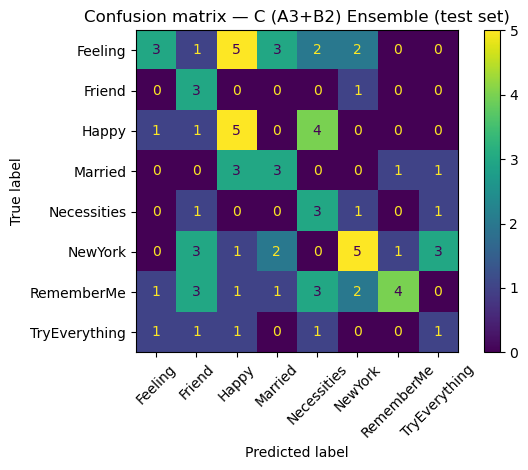

,Song,Val correct,Val total,Val acc,Test correct,Test total,Test acc
0,Feeling,2,13,0.15,3,16,0.19
1,Friend,2,7,0.29,3,4,0.75
2,Happy,8,13,0.62,5,11,0.45
3,Married,2,8,0.25,3,8,0.38
4,Necessities,4,5,0.80,3,6,0.50
5,NewYork,2,12,0.17,5,15,0.33
6,RememberMe,3,11,0.27,4,15,0.27
7,TryEverything,4,11,0.36,1,5,0.20


In [54]:
# retrieve deleted test files
test_df = df.query('speaker in @test_speaker_list')
file_paths_test = test_df['file_path'].values
labels_test     = test_df['label'].values

X_test_A3, _ = getXy(file_paths_test, labels_test, get_extended)
X_test_B2, _ = getXy(file_paths_test, labels_test, get_lbp_mel)
X_test_C = np.concatenate([X_test_A3, X_test_B2], axis=1)

X_train_C = np.concatenate([X_train_A3, X_train_B2], axis=1)
scaler_final = StandardScaler()
X_train_C_sc_final = scaler_final.fit_transform(X_train_C)
X_test_C_sc = scaler_final.transform(X_test_C)

best_model = VotingClassifier(estimators=[
    ('lr',  LogisticRegression(max_iter=1000, **{k.replace('clf__',''):v for k,v in best_params['C A3 + B2']['Logistic regression'].items()})),
    ('knn', KNeighborsClassifier(**{k.replace('clf__',''):v for k,v in best_params['C A3 + B2']['KNN'].items()})),
    ('svm', SVC(kernel='rbf', probability=True, **{k.replace('clf__',''):v for k,v in best_params['C A3 + B2']['SVM'].items()}))
], voting='soft')
best_model.fit(X_train_C_sc_final, y_train)

test_pred = best_model.predict(X_test_C_sc)
test_acc  = accuracy_score(labels_test, test_pred)
print(f'Final test accuracy: {test_acc:.3f}')
print(f'Random baseline:     {1/8:.3f}')

cm   = confusion_matrix(labels_test, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(xticks_rotation=45)
plt.title(f'Confusion matrix — C (A3+B2) Ensemble (test set)')
plt.tight_layout()
plt.show()

# per song accuracy comparison ( val vs test)
cm_val  = confusion_matrix(y_val, val_pred)
cm_test = confusion_matrix(labels_test, test_pred)

song_names = le.classes_
comparison = pd.DataFrame({
    'Song':      song_names,
    'Val correct':  np.diag(cm_val),
    'Val total':    cm_val.sum(axis=1),
    'Val acc':      np.round(np.diag(cm_val) / cm_val.sum(axis=1), 2),
    'Test correct': np.diag(cm_test),
    'Test total':   cm_test.sum(axis=1),
    'Test acc':     np.round(np.diag(cm_test) / cm_test.sum(axis=1), 2),
})
display(comparison)

The final test accuracy of 0.338 on completely unseen speakers is 2.7 times the random baseline of 0.125 and higher than the val accuracy 0.325, confirming the pipeline learned genuine song patterns. The confusion matrix comparison table reveals that the val and test partitions have quite different class sizes due to the speaker-level split, which affects the reliability of per song accuracy. Happy is the strongest performer across both partitions (0.62 val, 0.45 test), confirming its features are the most consistent and robust to speaker variation. Necessities had the highest val accuracy (0.80) but from only 5 clips, whereas on test with 6 clips it drops to 0.50, illustrating how sensitive accuracy is to small sample sizes. Friend jumps from 0.29 on val to 0.75 on test, but again from only 4 test clips, so this likely reflects a favourable speaker draw within the test set rather than genuine improvement. The songs that were weak on val ( Feeling (0.15) and NewYork (0.17) )  improve slightly on test (0.19 and 0.33), but remain among the hardest to classify. 

Both the validation and test sets contain around 80 clips across 8 classes so roughly 10 clips per song per partition. With samples this small, reported accuracies are very sensitive to which specific speakers and how many of each song ended up in each partition. A single misclassified clip changes accuracy by  1/80 = 0.0125, which is 1.25%. This means per song accuracy is highly volatile and individual shifts between val and test should not be over interpreted. Despite this there is still an overall pattern.Happy is consistently the strongest and Feeling, NewYork and RememberMe are consistently among the weakest.This shows that the model's weaknesses are consistent rather than random, pointing to genuine feature overlap between certain songs.
 

# 7 Conclusions


The final pipeline achieved a test accuracy of 0.338 on completely unseen speakers, above the random baseline of 0.125. 


Some acknowledged limitations of this project are:

1.The small dataset size. With 187 speakers and only approximately 80 clips in each evaluation partition, reported accuracies have high variance and may not reliably reflect true generalisation.

2. Loading clips from second 0 means opening noise from speaker preparation may have reduced feature quality for some clips.

3. The ensemble was trained using hyperparameters tuned individually per classifier via GridSearch, which are not necessarily optimal for the ensemble as a whole.

4. My model does not distinguishing between hums and whistles. Since the spectrograms showed they have very different frequency profiles this could have improved accuracy drawing different boundaries for each.

5. Same hyperparameters ranges were searched for all feature sets.  GridSearchCV searched the same parameter grid regardless of whether the feature set had 26 dimensions or 8699. The optimal C or K for a low dimensional space is likely very different from a high dimensional one. 


If I were to do the project again I would address all the limitations above and I would also:

1. Explore PCA component selection via crossv alidation rather than a fixed 100.
   
2. Explore A neural network transfer learning approach.

3.  Take  multiple overlapping 10 second windows from each clip ( if possible) rather than a single window would effectively increase the training set size without collecting new recordings.

 

# 
8 References

Acknowledge others here (books, papers, repositories, libraries, tools)

 1. Abdul Salam, M., Azar, A.T., Elgendy, M.S. and Fouad, K.M. (2021) The Effect of Different Dimensionality Reduction Techniques on Machine Learning Overfitting. Vol. 12, No. 4, 2021, pp. 1-67.

2. Lhoest, L., Lamrini, M., Vandendriessche, J., Wouters, N., da Silva, B., Chkouri, M.Y. and Touhafi, A. (2021) MosAIc: A Classical Machine Learning Multi-Classifier Based Approach against Deep Learning Classifiers for Embedded Sound Classification. Applied Sciences, 11(18), 8394. Available at: https://doi.org/10.3390/app11188394.

 3. Lim, H., Kim, M.J. and Kim, H. (2015) Robust Sound Event Classification Using LBP-HOG Based Bag-of-Audio-Words Feature Representation. Interspeech 2015, Dresden, Germany, pp. 330–334.

4. Masiha, S., Gohari, A., Yassaee, M.H. and Aref, M.R. (2022) 'Learning under Distribution Mismatch and Model Misspecification', arXiv preprint arXiv:2102.05695v3. Available at: https://arxiv.org/abs/2102.05695 (Accessed: 10 April 2026).

5. Pathan, K., Anitha, D., Amrutha, V., Kalyani, B., Mary, K. and Suchithra, E. (2025) Sound Classification and Using Spectrogram Image. International Journal of Computer Networks and Wireless Communications (IJCNWC), 15(2), pp. 1282–1287.

6. Rezaul, K.M., Jewel, M., Islam, M.S., Siddiquee, K.N.A., Barua, N., Rahman, M.A., Shan-A-Khuda, M., Sulaiman, R.B., Shaikh, M.S.I., Hamim, M.A., Tanmoy, F.M., Haque, A.U., Nipun, M.S., Dorudian, N., Kareem, A., Farid, A.K., Mubarak, A., Jannat, T. and Asha, U.F.T. (2024) 'Enhancing audio classification through MFCC feature extraction and data augmentation with CNN and RNN models', International Journal of Advanced Computer Science and Applications, 15(7). Available at: http://dx.doi.org/10.14569/IJACSA.2024.0150704 (Accessed: 15 April 2026).